In [6]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

# Satıcılar

🎯 Amacımız, diğerlerine göre tekrarlı olarak düşük performans gösteren satıcıları bulmak ve nedenini anlamaktır.  
Bu, Olist'in gelecekte kâr marjını artırmaya yönelik önerilerimizi şekillendirmemize yardımcı olacaktır.

## 1 - `olist/seller.py`  

`order.py` ile benzer bir süreçte, size `olist/seller.py` modülünü sunduk; içinde `Seller` sınıfı ve `Seller().get_training_data` yöntemi bulunuyor. Bu yöntem aşağıdaki özellikleri içeren bir DataFrame döndürür:

| feature_name | type | açıklama |
| --- | --- | --- |
| `seller_id` | str | satıcının benzersiz kimliği (UNIQUE) |
| `seller_city` | str | satıcının bulunduğu şehir |
| `seller_state` | str | satıcının bulunduğu eyalet |
| `delay_to_carrier` | float | sipariş, `shipping_limit_date`'den önce teslim edildiyse 0 döner; aksi takdirde gecikme süresini verir |
| `wait_time` | float | satıcı başına ortalama teslimat süresi (bekleme süresi) |
| `date_first_sale` | datetime | Olist üzerinde yapılan ilk satışın tarihi |
| `date_last_sale` | datetime | Olist üzerindeki son satışın tarihi |
| `months_on_olist` | float | Olist'te geçirilen yaklaşık ay sayısı |
| `share_of_five_stars` | float | satıcının yer aldığı siparişlerdeki beş yıldız değerlendirmelerinin oranı |
| `share_of_one_stars` | float | satıcının yer aldığı siparişlerdeki bir yıldız değerlendirmelerinin oranı |
| `review_score` | float | satıcının yer aldığı siparişler için ortalama değerlendirme puanı |
| `n_orders` | int | satıcının yer aldığı benzersiz sipariş sayısı |
| `quantity` | int | bu satıcı tarafından satılan toplam ürün adedi |
| `quantity_per_order` | float | bu satıcı için sipariş başına ortalama ürün sayısı |
| `sales` | float | bu satıcı ile ilişkili toplam satış tutarı (kargo hariç), BRL cinsinden |

❓ **Aşağıya yeni sınıfınızı import edin ve eğitim veri çerçevenizi inceleyin!** Kodları incelemek için zaman ayırın ve sizin için tam olarak nelerin hesaplandığını anlayın.

In [7]:
from olist.seller import Seller
seller = Seller()
training_data = seller.get_training_data()

🤔 Her satıcı için henüz hesaplanması gereken bir şey kaldı:
- Aşırı yüksek değerlendirmelerin oranı (`share_of_five_stars`) ve aşırı düşük değerlendirmelerin oranı (`share_of_one_stars`)
- (ortalama) `review_score`

😱 Düşük puanlı her sipariş Olist'in itibarına olumsuz etki yapar; bu etki `cost_of_review` ile modellenir.

Bu, daha sonra her satıcı için toplam `cost_of_review`'u hesaplamamıza yardımcı olacak!

❓ **Sizin doldurmanız gereken son metod: `get_review_score()`'u implemente edin.**

In [8]:
seller.data.keys()

dict_keys(['sellers', 'product_category_name_translation', 'orders', 'order_items', 'customers', 'geolocation', 'order_payments', 'order_reviews', 'products'])

In [9]:
items = seller.data["order_items"]
reviews = seller.data["order_reviews"]

df = reviews.merge(items , on="order_id")

In [10]:
df.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59,1,fd25ab760bfbba13c198fa3b4f1a0cd3,6d803cb79cc31c41c4c789a75933b3c7,2018-01-18 15:47:59,185.00,13.63
1,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59,2,fd25ab760bfbba13c198fa3b4f1a0cd3,6d803cb79cc31c41c4c789a75933b3c7,2018-01-18 15:47:59,185.00,13.63
2,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13,1,be0dbdc3d67d55727a65d4cd696ca73c,8e6d7754bc7e0f22c96d255ebda59eba,2018-03-06 12:48:39,79.79,8.30
3,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24,1,d1c427060a0f73f6b889a5c7c61f2ac4,a1043bafd471dff536d0c462352beb48,2018-02-08 10:31:15,149.00,45.12
4,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06,1,52c80cedd4e90108bf4fa6a206ef6b03,a1043bafd471dff536d0c462352beb48,2017-04-13 17:55:19,179.99,42.85


In [11]:
df.groupby("seller_id")["review_score"].mean().reset_index()

,seller_id,review_score
0,0015a82c2db000af6aaaf3ae2ecb0532,3.666667
1,001cca7ae9ae17fb1caed9dfb1094831,3.902542
2,001e6ad469a905060d959994f1b41e4f,1.000000
3,002100f778ceb8431b7a1020ff7ab48f,3.982143
4,003554e2dce176b5555353e4f3555ac8,5.000000
...,...,...
3085,ffcfefa19b08742c5d315f2791395ee5,1.000000
3086,ffdd9f82b9a447f6f8d4b91554cc7dd3,4.250000
3087,ffeee66ac5d5a62fe688b9d26f83f534,4.214286
3088,fffd5413c0700ac820c7069d66d98c89,3.866667


In [12]:
df = reviews.merge(items , on="order_id")

In [13]:
df = df.drop_duplicates(subset=["seller_id", "review_id"])

In [14]:
review_score = df.groupby("seller_id")["review_score"].mean().reset_index()

In [15]:
df["is_five_star"] = df["review_score"] == 5

In [16]:
five_stars = (
    df.groupby("seller_id")["is_five_star"]
    .mean()
    .reset_index()
    .rename(columns={"is_five_star": "share_of_five_stars"})
)

In [17]:
df["is_one_star"] = df["review_score"] == 1
one_stars = df.groupby("seller_id")["is_one_star"].mean().reset_index()
one_stars = one_stars.rename(
    columns = {"is_one_star" : "share_of_one_stars"}
)

In [18]:
from olist.seller import Seller

seller = Seller()
sellers = seller.get_review_score().head()

🧪 Kodunuzu aşağıda test edin

In [19]:
from nbresult import ChallengeResult

tmp = Seller().get_training_data()
result = ChallengeResult('seller',
    shape = tmp.shape,
    median = tmp.review_score.median(),
    columns = tmp.columns
)
result.write()
print(result.check())


============================= test session starts ==============================
platform darwin -- Python 3.12.9, pytest-9.1.1, pluggy-1.7.0 -- /Users/serenkayran/.pyenv/versions/workintech/bin/python
cachedir: .pytest_cache
rootdir: /Users/serenkayran/Workintech/week1/day5/data-sellers/tests
plugins: platformdirs-4.13.5
collecting ... collected 3 items

test_seller.py::TestSeller::test_column_names PASSED                     [ 33%]
test_seller.py::TestSeller::test_median_review_score PASSED              [ 66%]
test_seller.py::TestSeller::test_shape PASSED                            [100%]

============================== 3 passed in 0.27s ===============================


💯 You can commit your code:

git add tests/seller.pickle

git commit -m 'Completed seller step'

git push origin master



💡 **Tam satır sayısını elde edemiyor musunuz?**
<details><summary>Fazladan 3 satır mı var?</summary>
Left veya right join mi yaptınız? Nedenini anlıyoruz; fakat burada sadece değerlendirme alan satıcılarla ilgileniyoruz; bu yüzden inner join kullandık.
</details>
<details><summary>2 satır mı eksik?</summary>
`Orders().get_training_data()`'ı mı kullandınız? Bu geçerli bir seçenek, fakat sadece değerlendirmelerle ilgileniyorsak biraz aşırı olabilir. O method birçok hesaplama yapar ve döndürdüğü sütunların çoğuna ihtiyaç duymuyoruz. İhtiyacımıza daha uygun başka bir `Order` methodu bulun.
</details>

⚠️ `olist` reposundaki `seller.py` dosyasına yaptığınız kod değişikliklerini commit etmeyi unutmayın!

## 2 - Satıcıları İnceleme

### (2.1) Görselleştirmeler

Bu satıcılar hakkında ilk ***`EDA - Keşifsel Veri Analizi`*** ile başlayalım.

👉 `sellers` için özet istatistiklere bakın. Satıcı başına siparişlerin medyanı nedir ❓

👉 Bir sonraki adımda, veri setindeki her sayısal değişkenin dağılımını tek bir büyük görselde çizeceğiz. 

Kod size verildi, hücreyi çalıştırmanız yeterli.

- 👀 Herhangi bir aykırı değer fark ediyor musunuz?
- Sipariş sayısının dağılımı nasıl görünüyor ❓

In [20]:
seller = Seller()
sellers = seller.get_training_data()

sellers.describe()

,delay_to_carrier,wait_time,date_first_sale,date_last_sale,months_on_olist,n_orders,quantity,quantity_per_order,sales,review_score,share_of_five_stars,share_of_one_stars
count,2967.000000,2967.000000,2967,2967,2967.000000,2967.000000,2967.000000,2967.000000,2967.000000,2967.000000,2967.000000,2967.000000
mean,0.385636,12.139417,2017-10-23 20:09:55.342096,2018-04-25 09:37:50.292551,6.116616,33.650489,37.897203,1.157337,4568.852187,4.101782,0.595153,0.120820
min,0.000000,1.214178,2016-09-15 12:16:38,2016-10-06 15:44:56,0.000000,1.000000,1.000000,1.000000,6.500000,1.000000,0.000000,0.000000
25%,0.000000,8.287658,2017-04-25 08:04:06.500000,2018-02-13 09:27:30,1.000000,2.000000,3.000000,1.000000,239.850000,3.846154,0.493704,0.000000
50%,0.000000,11.115143,2017-11-09 18:35:42,2018-07-19 14:30:17,4.000000,7.000000,8.000000,1.000000,896.000000,4.210884,0.600000,0.058824
75%,0.000000,14.231984,2018-04-24 18:21:19,2018-08-17 08:35:23,10.000000,23.000000,26.000000,1.142857,3583.995000,4.626453,0.750000,0.159043
max,45.434039,189.863160,2018-08-28 09:44:14,2018-09-03 17:40:06,23.000000,1854.000000,2033.000000,15.000000,229472.630000,5.000000,1.000000,1.000000
std,2.295812,7.069233,NaN,NaN,6.085524,107.182856,121.514362,0.439557,14191.836779,0.801274,0.278675,0.188787


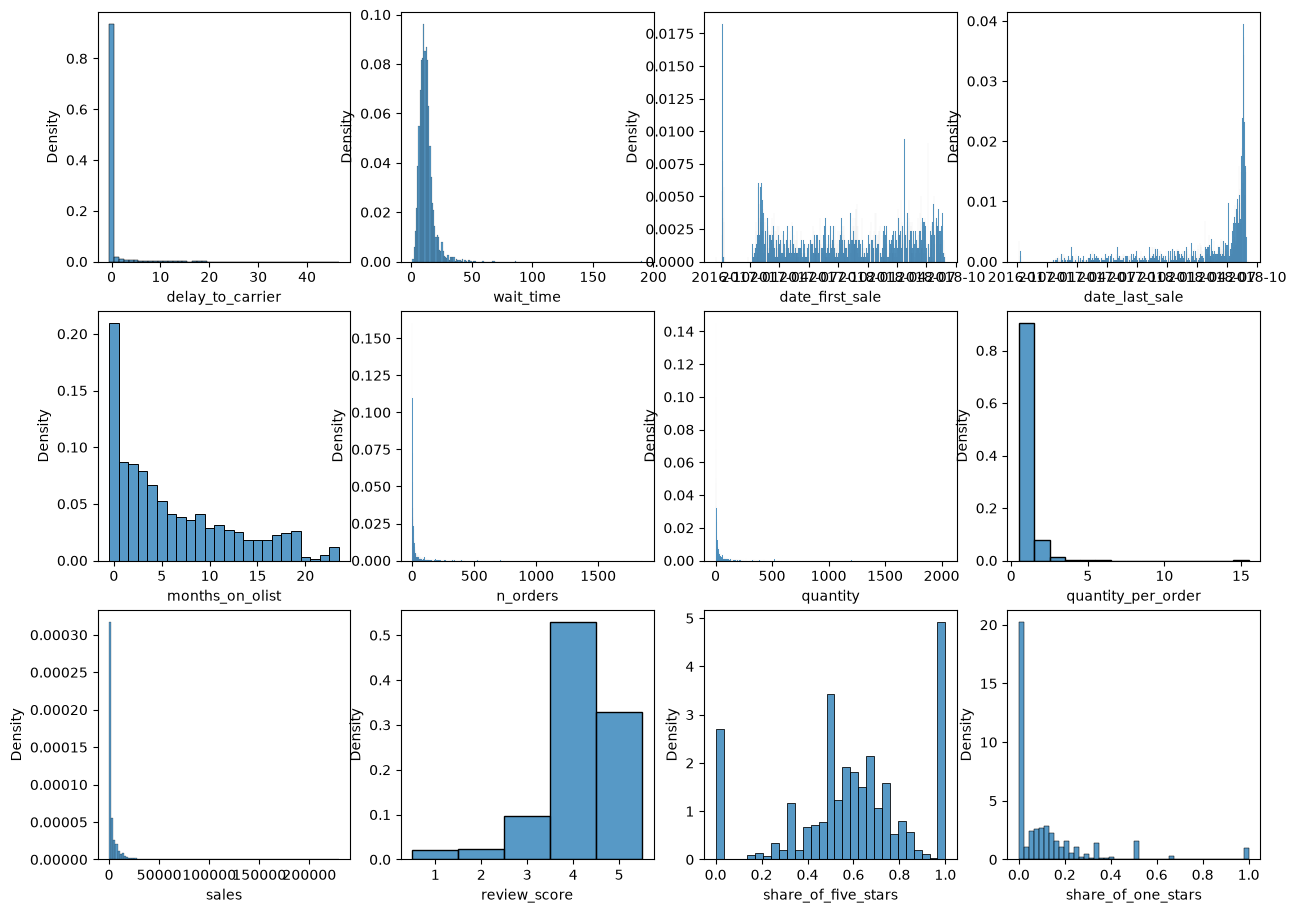

In [21]:
plt.figure(figsize=(15,11))
for (i, col) in enumerate(sellers.describe().columns):#["wait_time", "delay_to_carrier", "avg_review_score", "n_orders", "quantity", "price"]):
    plt.subplot(3,4,i+1)
    sns.histplot(sellers[col], kde=False, stat='density', discrete=[True,None][col in ['share_of_one_stars','share_of_five_stars','sales']]);

💡 Çok düşük değerlendirme puanlarına sahip bir grup satıcının öne çıktığı görünüyor!

📊 Grafiksel olarak inceleyelim:
- `plotly` kullanarak `delay_to_carrier` ile `wait_time` arasındaki ilişkiyi gösteren bir saçılma grafiği (scatterplot) oluşturuyoruz; kabarcık boyutunu satıcının toplam `sales`'i, rengini ise `review_score` belirliyor.

`plotly`'ı daha sonra detaylı göreceğiz; şimdilik aşağıdaki hücreyi çalıştırın.

In [22]:
import plotly.express as px
fig = px.scatter(data_frame = sellers[sellers['review_score'] < 4],
    x="wait_time",
    y="delay_to_carrier",
    size="sales",
    color="review_score",
    size_max = 60,
    opacity = 0.5
)
fig.show()

En kötü satıcıları bulmak için `x`, `y`, `color` ve `size` değerlerini değiştirmekten çekinmeyin.

### (2.2) `review_score`'u OLS ile modelleme

⚠️ Saçılma grafikleri veriyi görsel olarak analiz etmemizi sağlar, fakat sınırlamaları vardır: deneme-yanılma içerir ve ilişkileri yalnızca niteliksel değerlendiririz.

💡 **Satıcıların `review_score`** değişkenini açıklamak için daha sağlam bir yöntem, `statsmodels` içinde **çok değişkenli (multivariate) OLS** kullanarak çeşitli özelliklerin `review_score` üzerindeki etkisini modellemektir.

İstediğiniz sayısal özellikleri kullanarak bir OLS oluşturalım.

👉 Regresyon katsayılarını karşılaştırabilmek için önce aşağıdaki `standardize` fonksiyonunu kullanarak özelliklerinizi standardize edin.

In [ ]:
def standardize(df, features):
    """Standardize specified numerical features in a DataFrame using z-score.

    Parameters
    ----------
    df : pandas.DataFrame
        Input dataframe.
    features : list of str
        List of column names to standardize.

    Returns
    -------
    pandas.DataFrame
        A copy of the original dataframe where the specified features have been
        standardized to zero mean and unit variance. Other columns are left
        unchanged.
    """
    df_standardized = df.copy()
    mu = df[features].mean()
    sigma = df[features].std() #Seçilen sütunların standart sapmasını hesaplar.
    df_standardized[features] = (df[features] - mu) / sigma #Her değerden ortalamayı çıkarır ve standart sapmaya böler. Yani Z-score standardizasyonu yapar.
    return df_standardized #Standartlaştırılmış DataFrame'i döndürür. Orijinal sellers tablosu değişmez.

In [ ]:
features = ["wait_time", "delay_to_carrier", "sales"] #Modelde kullanacağımız üç bağımsız değişkeni seçtik.
sellers_std = standardize(sellers, features)
sellers_std[features].describe() #Standartlaştırma başarılı mı diye kontrol ettik.

,wait_time,delay_to_carrier,sales
count,2.967000e+03,2.967000e+03,2.967000e+03
mean,-2.197246e-16,-9.579275e-18,-6.046917e-17
std,1.000000e+00,1.000000e+00,1.000000e+00
min,-1.545463e+00,-1.679737e-01,-3.214772e-01
25%,-5.448623e-01,-1.679737e-01,-3.050347e-01
50%,-1.448919e-01,-1.679737e-01,-2.588003e-01
75%,2.960105e-01,-1.679737e-01,-6.939603e-02
max,2.514046e+01,1.962199e+01,1.584740e+01


Ekranında mean değerleri şöyle görünüyor:
-2.197246e-16
Bu bilimsel gösterimdir ve yaklaşık sıfıra eşittir. Hata değildir.

👉 Sonraki adımda bir OLS modeli oluşturun ve fit edin.

In [26]:
model = smf.ols(formula=f"review_score ~ {'+ '.join(features)}", data=sellers_std).fit()

❓ En etkili özellikler hangileri?

👉 Sıralanmış katsayılarla bir 📊 `bar_plot` çizin.

👉 Son olarak modelinizin performansını (`R-squared`) ve `residuals`'ı inceleyin

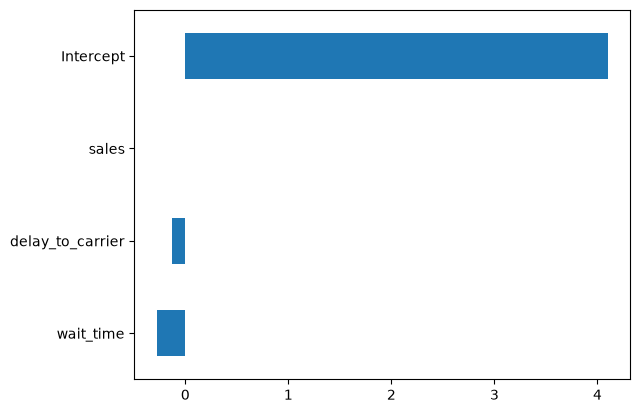

In [ ]:
model.params.sort_values().plot(kind="barh")
plt.show()

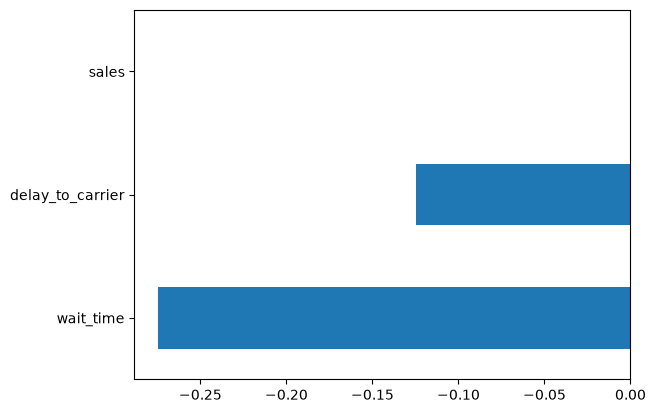

In [29]:
model.params.drop("Intercept").sort_values().plot(kind="barh")
plt.show()

👉 Gerçek değerlendirme puanlarını ve modelin tahmin ettiği puanları aynı grafikte göstererek karşılaştırın.

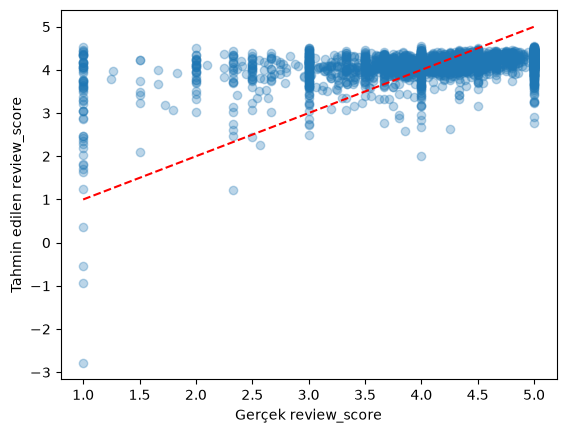

In [30]:
plt.scatter(sellers_std["review_score"], model.fittedvalues, alpha=0.3)
plt.plot([1, 5], [1, 5], "r--")
plt.xlabel("Gerçek review_score")
plt.ylabel("Tahmin edilen review_score")
plt.show()

👉 Artıkları (residuals) görselleştirin

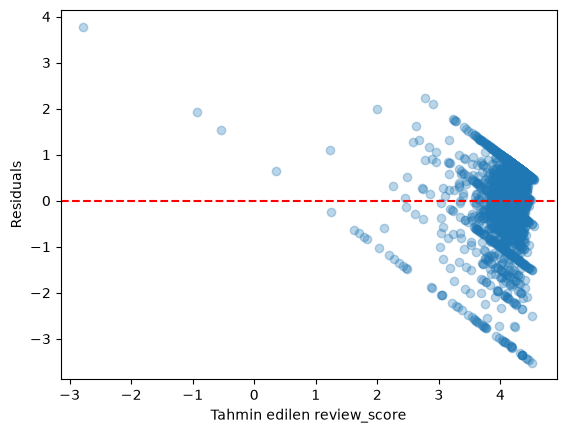

In [31]:
plt.scatter(model.fittedvalues, model.resid, alpha=0.3)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Tahmin edilen review_score")
plt.ylabel("Residuals")
plt.show()

### (2.3) Analize `seller_state` bilgisini ekleyin

❓ Henüz `seller_state` bilgisini kullanmadık.  
- Sadece `seller_state`'lere karşı `review_score`'u regresyonla modelleyen yeni bir OLS oluşturun.
- `olist/utils.py` içinde sizin için yazılmış olan `return_significative_coef(model)` fonksiyonunu kullanarak anlamlı (significant) özellikleri analiz edin.
- `review_score` açısından en iyi eyaletler hangileri?

<details>
    <summary>- İpuçları -</summary>
        
⚠️ Dikkat, `seller_state` kategorik bir özelliktir. 
    
💡 Formülde kategorik değişkenleri belirtmek için `C(a_cat_feature)` kullanın. Bu, her benzersiz kategori için bir boolean değişken (`is_cat_feature_xx`) oluşturacaktır.

</details>

In [32]:
state_model = smf.ols(
    formula="review_score ~ C(seller_state)",
    data=sellers
).fit()

state_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           review_score   R-squared:                       0.007
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                    0.9782
Date:                Wed, 28 Oct 2026   Prob (F-statistic):              0.487
Time:                        23:13:44   Log-Likelihood:                -3541.8
No. Observations:                2967   AIC:                             7128.
Df Residuals:                    2945   BIC:                             7260.
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
=========================================================================================
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 2.3333      0.801      2.912      0.004       0.762       3.905
C(seller_state)[T.BA]     1.7617      0.823      2.140      0.032       0.147       3.376
C(seller_state)[T.CE]     1.3461      0.834      1.614      0.107      -0.289       2.981
C(seller_state)[T.DF]     1.6988      0.815      2.085      0.037       0.102       3.296
C(seller_state)[T.ES]     2.0775      0.819      2.536      0.011       0.471       3.684
C(seller_state)[T.GO]     1.8102      0.812      2.231      0.026       0.219       3.401
C(seller_state)[T.MA]     1.6590      1.133      1.464      0.143      -0.563       3.881
C(seller_state)[T.MG]     1.8100      0.803      2.254      0.024       0.235       3.385
C(seller_state)[T.MS]     1.9545      0.878      2.227      0.026       0.233       3.676
C(seller_state)[T.MT]     1.8898      0.896      2.109      0.035       0.133       3.647
C(seller_state)[T.PA]     2.1667      1.133      1.912      0.056      -0.055       4.389
C(seller_state)[T.PB]     1.9306      0.866      2.230      0.026       0.233       3.628
C(seller_state)[T.PE]     1.7905      0.845      2.120      0.034       0.134       3.447
C(seller_state)[T.PI]     1.7500      1.133      1.544      0.123      -0.472       3.972
C(seller_state)[T.PR]     1.8289      0.803      2.279      0.023       0.255       3.402
C(seller_state)[T.RJ]     1.7655      0.804      2.196      0.028       0.189       3.342
C(seller_state)[T.RN]     2.1424      0.878      2.441      0.015       0.421       3.864
C(seller_state)[T.RO]     1.5208      0.981      1.550      0.121      -0.404       3.445
C(seller_state)[T.RS]     1.8158      0.805      2.257      0.024       0.238       3.393
C(seller_state)[T.SC]     1.8326      0.804      2.281      0.023       0.257       3.408
C(seller_state)[T.SE]     1.5167      0.981      1.545      0.122      -0.408       3.441
C(seller_state)[T.SP]     1.7400      0.802      2.171      0.030       0.168       3.312
==============================================================================
Omnibus:                      943.713   Durbin-Watson:                   2.061
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2922.548
Skew:                          -1.628   Prob(JB):                         0.00
Kurtosis:                       6.611   Cond. No.                         308.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

☝️ Bazı eyaletlerin ortalama olarak diğerlerinden _anlamlı_ biçimde daha iyi değerlendirmelere sahip olduğu görülebilir.

🤔 Bu, daha düşük `quantity_per_order`, daha kısa `wait_time` veya `delay_to_carrier`'dan mı kaynaklanıyor? Yoksa elimizde olmayan başka faktörlerden mi?

❓ **`seller_state` etkisini diğerlerinden izole etmeye çalışın: OLS modelinize sürekli (continuous) diğer özellikleri ekleyin; `seller_state` artık istatistiksel olarak anlamlı olmayana kadar devam edin!**

In [33]:
from olist.utils import return_significative_coef

return_significative_coef(state_model)

,variable,p_value,coef
0,Intercept,0.003620,2.333333
16,C(seller_state)[T.RN],0.014723,2.142381
4,C(seller_state)[T.ES],0.011276,2.077548
8,C(seller_state)[T.MS],0.026055,1.954474
11,C(seller_state)[T.PB],0.025792,1.930556
9,C(seller_state)[T.MT],0.034998,1.889815
19,C(seller_state)[T.SC],0.022637,1.832569
14,C(seller_state)[T.PR],0.022744,1.828906
18,C(seller_state)[T.RS],0.024086,1.815770
5,C(seller_state)[T.GO],0.025785,1.810196


In [34]:
state_model_2 = smf.ols(
    formula="review_score ~ C(seller_state) + wait_time + delay_to_carrier + sales + quantity_per_order",
    data=sellers_std
).fit()

return_significative_coef(state_model_2)

,variable,p_value,coef
0,Intercept,1.330502e-07,3.828261
25,quantity_per_order,6.122555e-04,-0.103384
23,delay_to_carrier,1.256034e-15,-0.120757
22,wait_time,5.574256e-72,-0.279503


☝️ Analize `wait_time` ekledikten sonra, 22 adet `is_seller_state_xx` dummy değişkeninin hiçbirinin istatistiksel olarak anlamlı olmadığı görüldü:

Küçük veri setimiz göz önüne alındığında (çoğu eyalette çok az sayıda satıcı var):
- "Bazı eyaletlerin, `wait_time` dışındaki nedenlerle doğal olarak diğerlerinden daha iyi olduğu" sonucuna _varamayız_.
- Başka bir deyişle, "`seller_state`'in `wait_time` dışında `review_score` üzerinde etkisi yoktur" hipotezini reddedemeyiz.

🏁 Tebrikler!

💾 Commit ve push yapın:
- `sellers.ipynb` not defterinizi
- ayrıca `seller.py` dosyanızı